In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [3]:
dataset = build_dataset('test')
valid_dataset = build_dataset('valid')

In [4]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
baseline = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)

## Warm Start Diffusion

In [5]:
ws_unet = ModelResults('132-warmstart-deeplabv3plus', 'warm-start-unet', 199, 'test', dataset)
wsd_ddpm_1000 = ModelResults('133-wsd', 'ddpm-1000', 199, 'test', dataset)
wsd_ddpm_500 = ModelResults('133-wsd', 'ddpm-500', 199, 'test', dataset)
wsd_ddpm_100 = ModelResults('133-wsd', 'ddpm-100', 199, 'test', dataset)
wsd_ddpm_50 = ModelResults('133-wsd', 'ddpm-50', 199, 'test', dataset)
wsd_ddpm_10 = ModelResults('133-wsd', 'ddpm-10', 199, 'test', dataset)
wsd_ddpm_5 = ModelResults('133-wsd', 'ddpm-5', 199, 'test', dataset)
wsd_ddpm_4 = ModelResults('133-wsd', 'ddpm-4', 199, 'test', dataset)
wsd_ddpm_3 = ModelResults('133-wsd', 'ddpm-3', 199, 'test', dataset)
wsd_ddpm_2 = ModelResults('133-wsd', 'ddpm-2', 199, 'test', dataset)
wsd_ddpm_1 = ModelResults('133-wsd', 'ddpm-1', 199, 'test', dataset)

In [6]:
comparison = ModelComparison(
  [unet_baseline, baseline, ws_unet, wsd_ddpm_1000],
  ['U-Net Baseline', 'Diffusion Baseline', 'Warm-Start U-Net', 'Warm-Start Diffusion'],
)

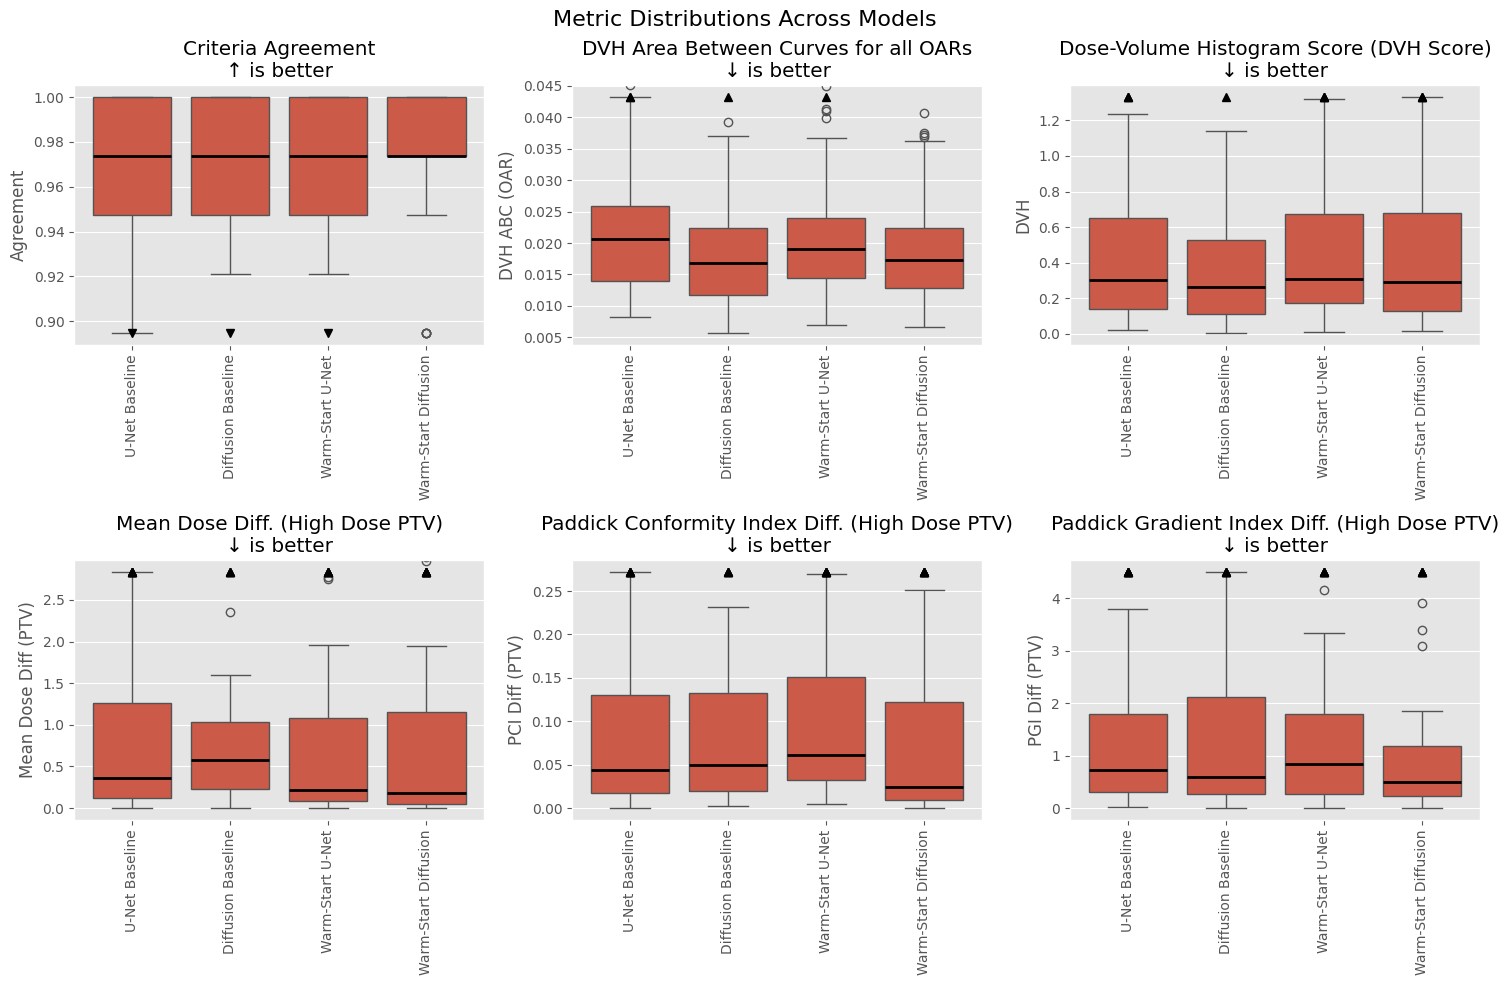

In [8]:
_ = comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

In [9]:
wsd_ddpm_comparison = ModelComparison(
  [wsd_ddpm_1000, wsd_ddpm_500, wsd_ddpm_100, wsd_ddpm_50, wsd_ddpm_10, wsd_ddpm_5, wsd_ddpm_4, wsd_ddpm_3, wsd_ddpm_2, wsd_ddpm_1],
  ['WSD DDPM T=1000', 'WSD DDPM T=500', 'WSD DDPM T=100', 'WSD DDPM T=50', 'WSD DDPM T=10', 'WSD DDPM T=5', 'WSD DDPM T=4', 'WSD DDPM T=3', 'WSD DDPM T=2', 'WSD DDPM T=1'],
)

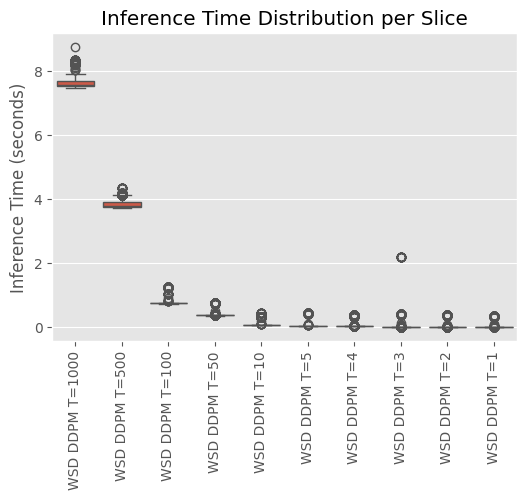

In [10]:
_ = wsd_ddpm_comparison.plot_inference_times('slice', 'seconds')

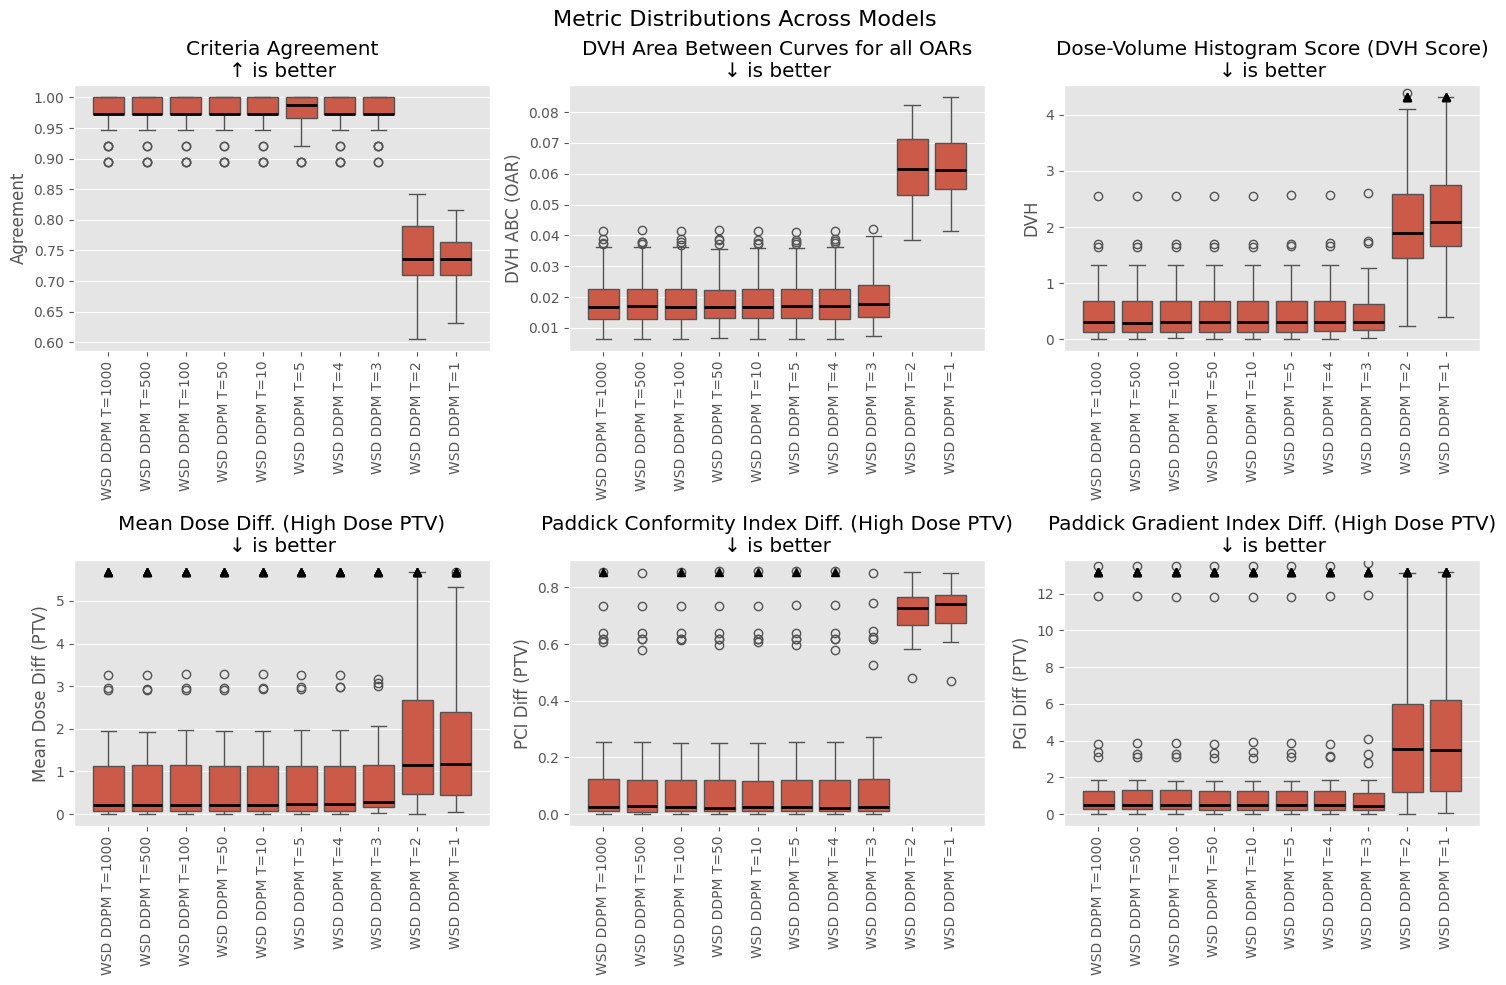

In [11]:
_ = wsd_ddpm_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

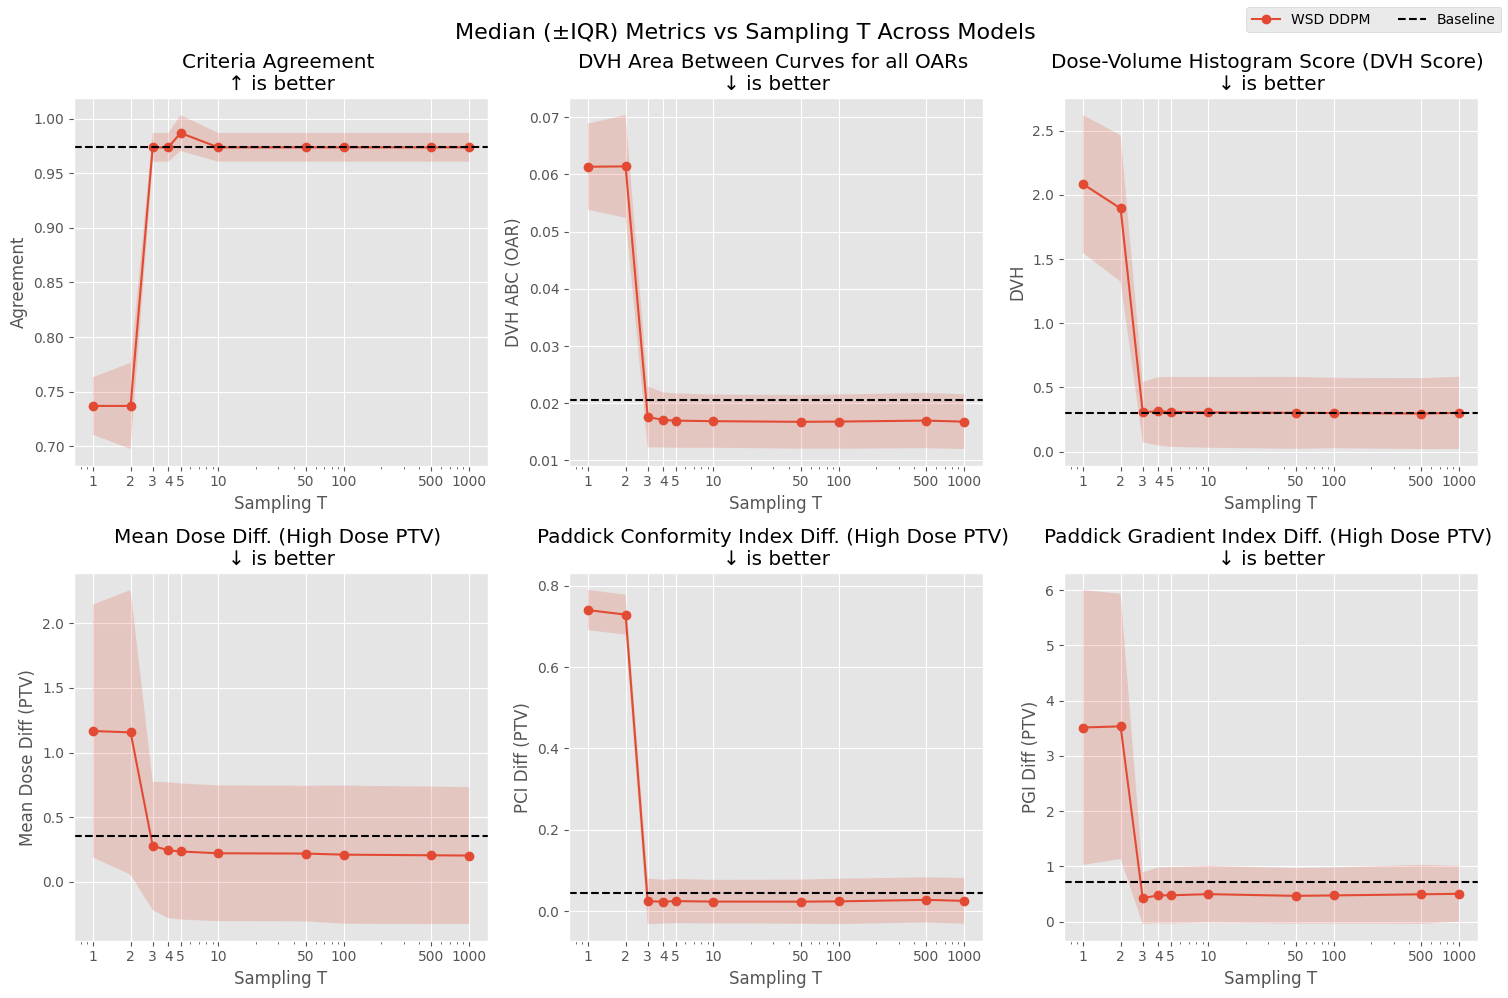

In [12]:
_ = wsd_ddpm_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)

In [13]:
wsd_ddim_1000 = ModelResults('133-wsd', 'ddim-1000', 199, 'test', dataset)
wsd_ddim_500 = ModelResults('133-wsd', 'ddim-500', 199, 'test', dataset)
wsd_ddim_100 = ModelResults('133-wsd', 'ddim-100', 199, 'test', dataset)
wsd_ddim_50 = ModelResults('133-wsd', 'ddim-50', 199, 'test', dataset)
wsd_ddim_10 = ModelResults('133-wsd', 'ddim-10', 199, 'test', dataset)
wsd_ddim_5 = ModelResults('133-wsd', 'ddim-5', 199, 'test', dataset)
wsd_ddim_4 = ModelResults('133-wsd', 'ddim-4', 199, 'test', dataset)
wsd_ddim_3 = ModelResults('133-wsd', 'ddim-3', 199, 'test', dataset)
wsd_ddim_2 = ModelResults('133-wsd', 'ddim-2', 199, 'test', dataset)
wsd_ddim_1 = ModelResults('133-wsd', 'ddim-1', 199, 'test', dataset)

In [14]:
wsd_comparison = ModelComparison(
  [wsd_ddpm_1000, wsd_ddpm_500, wsd_ddpm_100, wsd_ddpm_50, wsd_ddpm_10, wsd_ddpm_5, wsd_ddpm_4, wsd_ddpm_3, wsd_ddpm_2, wsd_ddpm_1,
   wsd_ddim_1000, wsd_ddim_500, wsd_ddim_100, wsd_ddim_50, wsd_ddim_10, wsd_ddim_5, wsd_ddim_4, wsd_ddim_3, wsd_ddim_2, wsd_ddim_1],
  ['WSD DDPM T=1000', 'WSD DDPM T=500', 'WSD DDPM T=100', 'WSD DDPM T=50', 'WSD DDPM T=10', 'WSD DDPM T=5', 'WSD DDPM T=4', 'WSD DDPM T=3', 'WSD DDPM T=2', 'WSD DDPM T=1',
   'WSD DDIM T=1000', 'WSD DDIM T=500', 'WSD DDIM T=100', 'WSD DDIM T=50', 'WSD DDIM T=10', 'WSD DDIM T=5', 'WSD DDIM T=4', 'WSD DDIM T=3', 'WSD DDIM T=2', 'WSD DDIM T=1'],
)

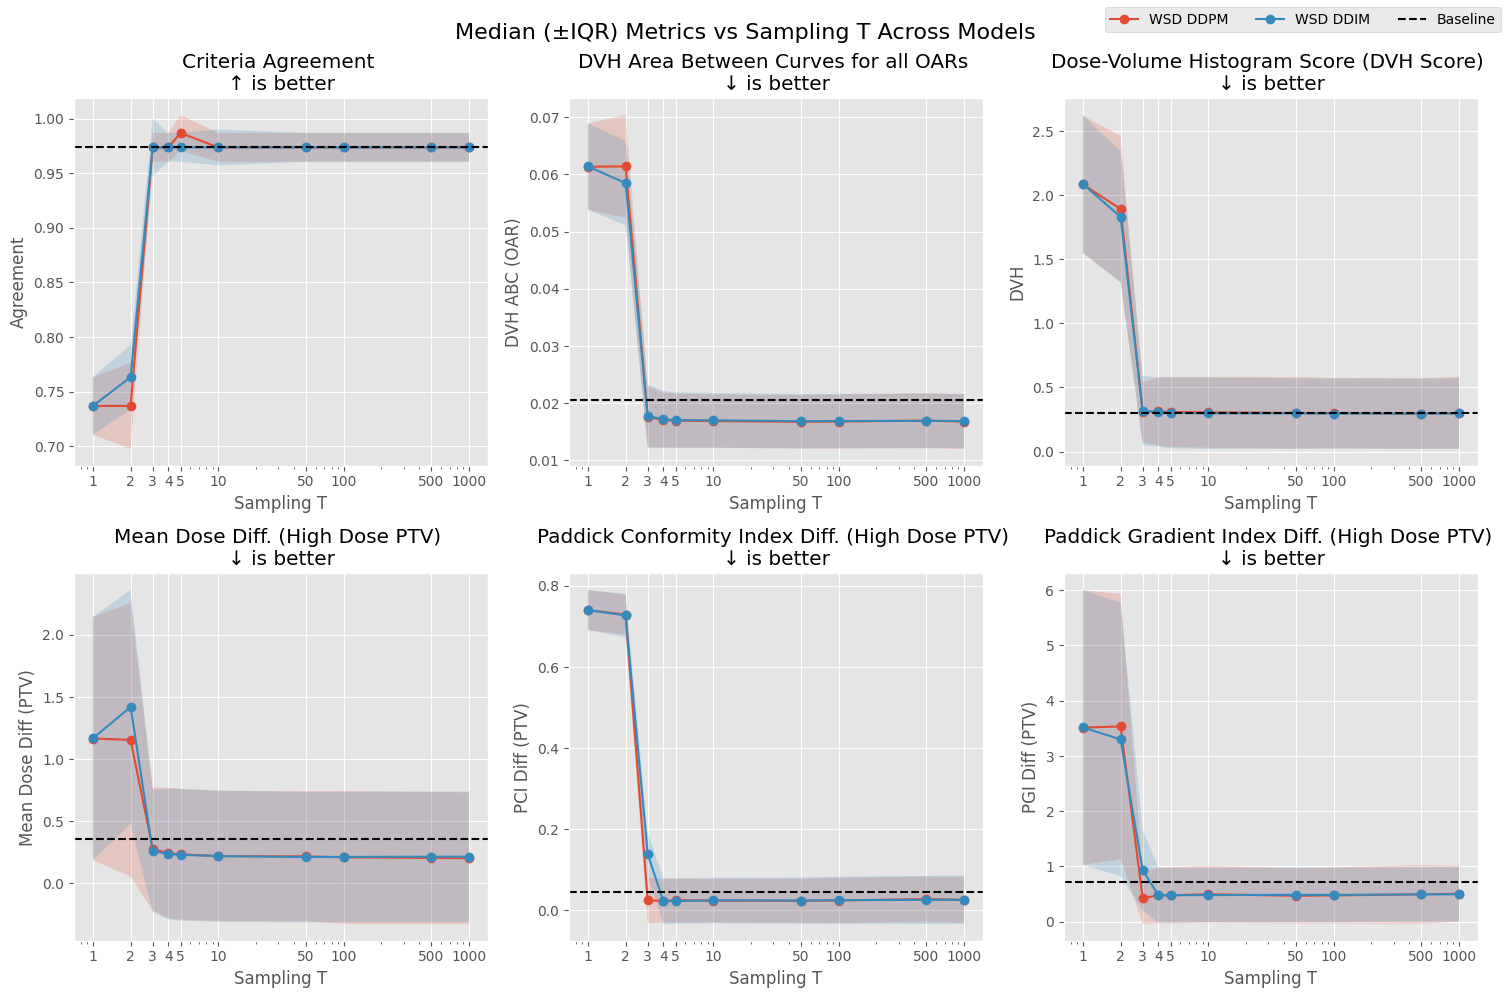

In [15]:
_ = wsd_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)

## Inversion by Direct Iteration

In [10]:
indi_1000 = ModelResults('141-indi-deeplabv3plus', 'indi-1000', 199, 'test', dataset)
indi_500 = ModelResults('141-indi-deeplabv3plus', 'indi-500', 199, 'test', dataset)
indi_100 = ModelResults('141-indi-deeplabv3plus', 'indi-100', 199, 'test', dataset)
indi_50 = ModelResults('141-indi-deeplabv3plus', 'indi-50', 199, 'test', dataset)
indi_10 = ModelResults('141-indi-deeplabv3plus', 'indi-10', 199, 'test', dataset)
indi_5 = ModelResults('141-indi-deeplabv3plus', 'indi-5', 199, 'test', dataset)
indi_4 = ModelResults('141-indi-deeplabv3plus', 'indi-4', 199, 'test', dataset)
indi_3 = ModelResults('141-indi-deeplabv3plus', 'indi-3', 199, 'test', dataset)
indi_2 = ModelResults('141-indi-deeplabv3plus', 'indi-2', 199, 'test', dataset)
indi_1 = ModelResults('141-indi-deeplabv3plus', 'indi-1', 199, 'test', dataset)

In [11]:
indi_comparison = ModelComparison(
  [indi_1000, indi_500, indi_100, indi_50, indi_5, indi_4, indi_3, indi_2, indi_1],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1']
)

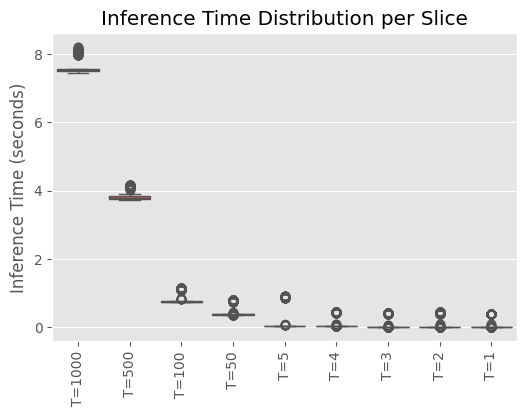

In [12]:
_ = indi_comparison.plot_inference_times('slice', 'seconds')

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

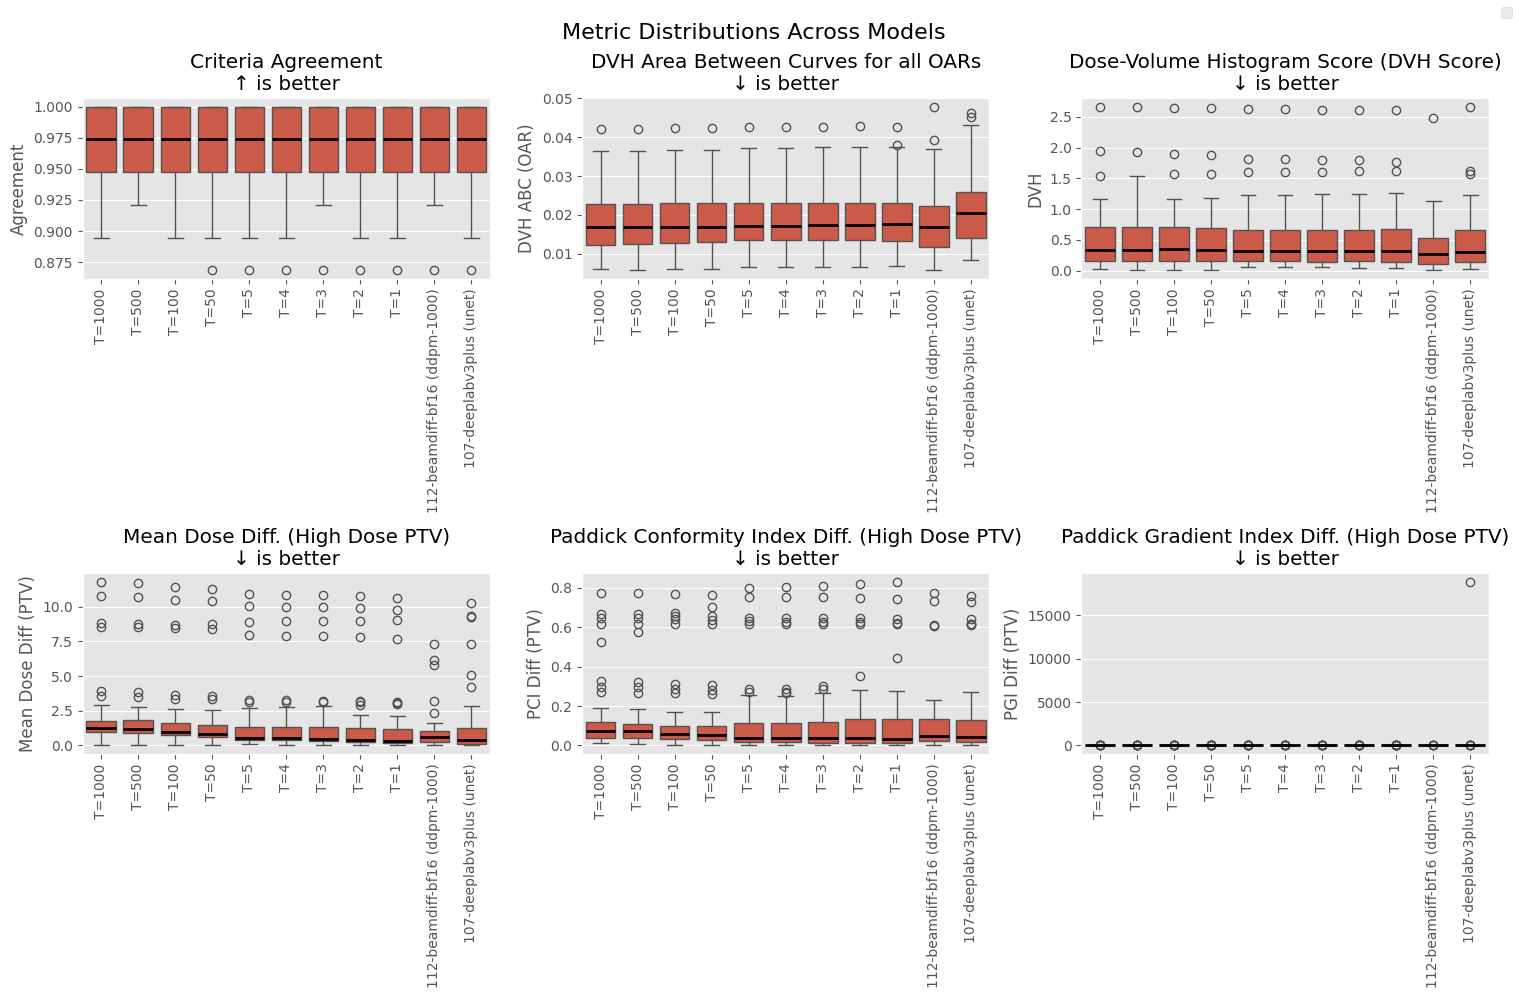

In [13]:
_ = (indi_comparison + baseline + unet_baseline).plot_metric_distributions(METRICS_PRED, outliers=True)

## Late-Stage Diffusion Refinement

In [20]:
lsdr_ddpm_100 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddpm-100', 199, 'test', dataset)
lsdr_ddpm_50 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddpm-50', 199, 'test', dataset)
lsdr_ddpm_10 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddpm-10', 199, 'test', dataset)
lsdr_ddpm_5 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddpm-5', 199, 'test', dataset)
lsdr_ddpm_1 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddpm-1', 199, 'test', dataset)

lsdr_ddim_100 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddim-100', 199, 'test', dataset)
lsdr_ddim_50 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddim-50', 199, 'test', dataset)
lsdr_ddim_10 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddim-10', 199, 'test', dataset)
lsdr_ddim_5 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddim-5', 199, 'test', dataset)
lsdr_ddim_1 = ModelResults('112-beamdiff-bf16', 'lsdr-107-ddim-1', 199, 'test', dataset)

In [21]:
lsdr_ddpm_comparison = ModelComparison(
  [lsdr_ddpm_100, lsdr_ddpm_50, lsdr_ddpm_10, lsdr_ddpm_5, lsdr_ddpm_1],
  ['T=100', 'T=50', 'T=10', 'T=5', 'T=1']
)

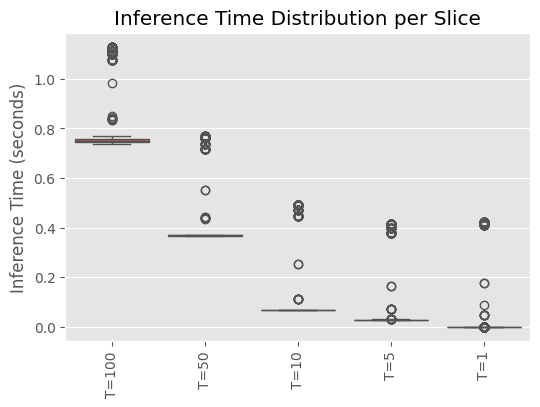

In [22]:
_ = lsdr_ddpm_comparison.plot_inference_times('slice', 'seconds')

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

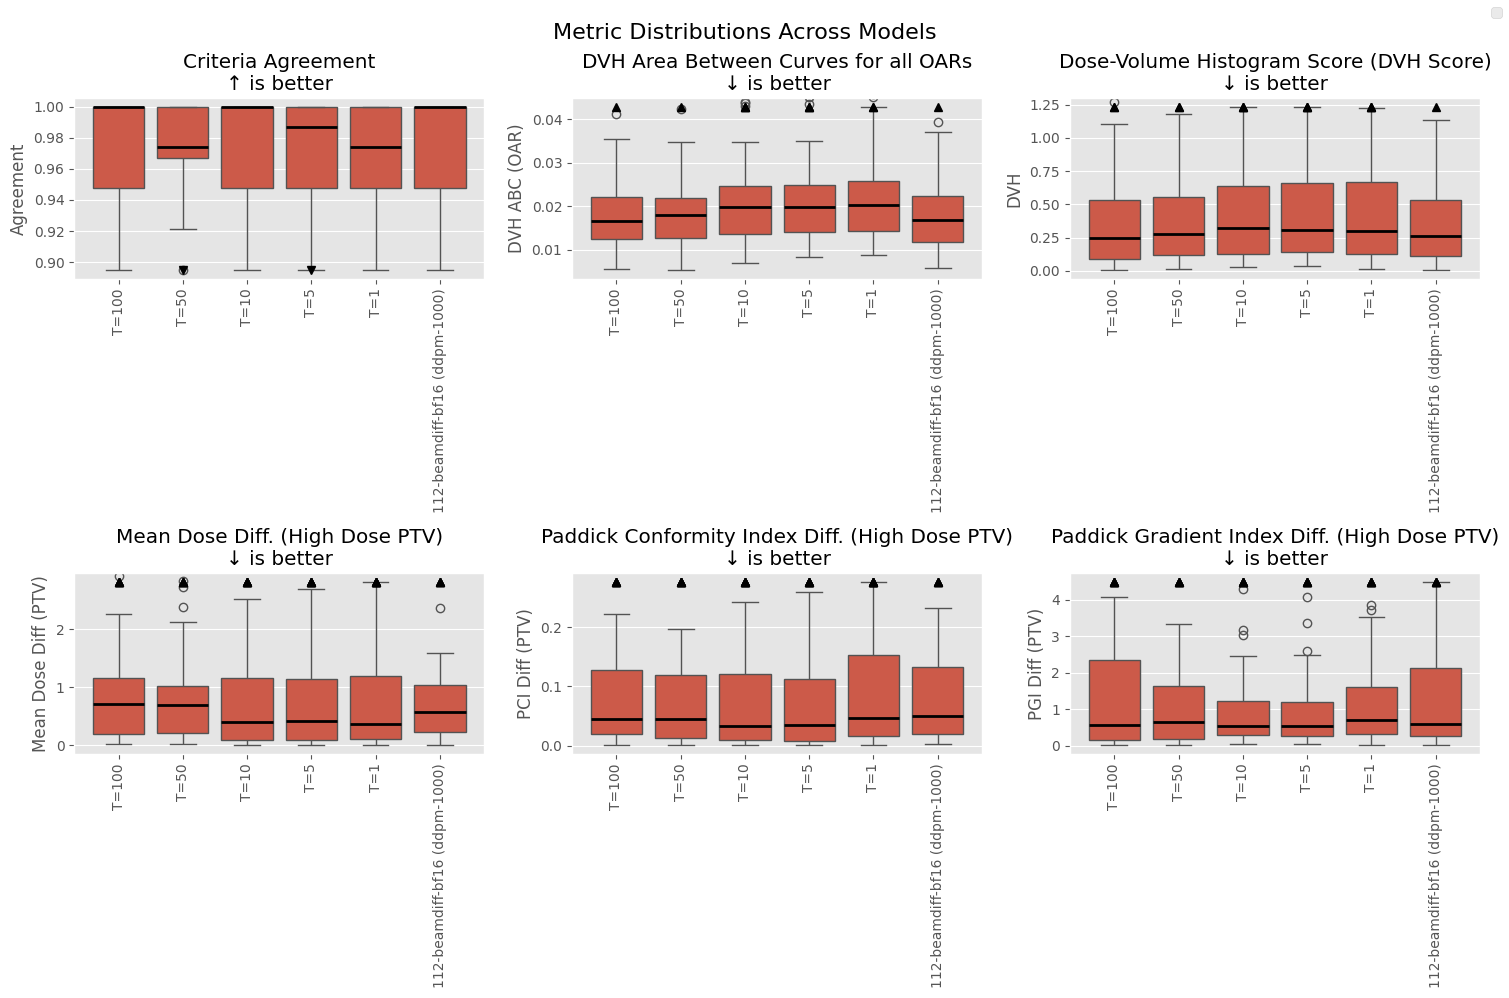

In [31]:
_ = (lsdr_ddpm_comparison + baseline).plot_metric_distributions(METRICS_PRED, outliers=False)

## Analytical Dose

In [25]:
analytical_dose = ModelResults('142-analytical-dose', 'warm-start-unet', 0, 'valid', valid_dataset)

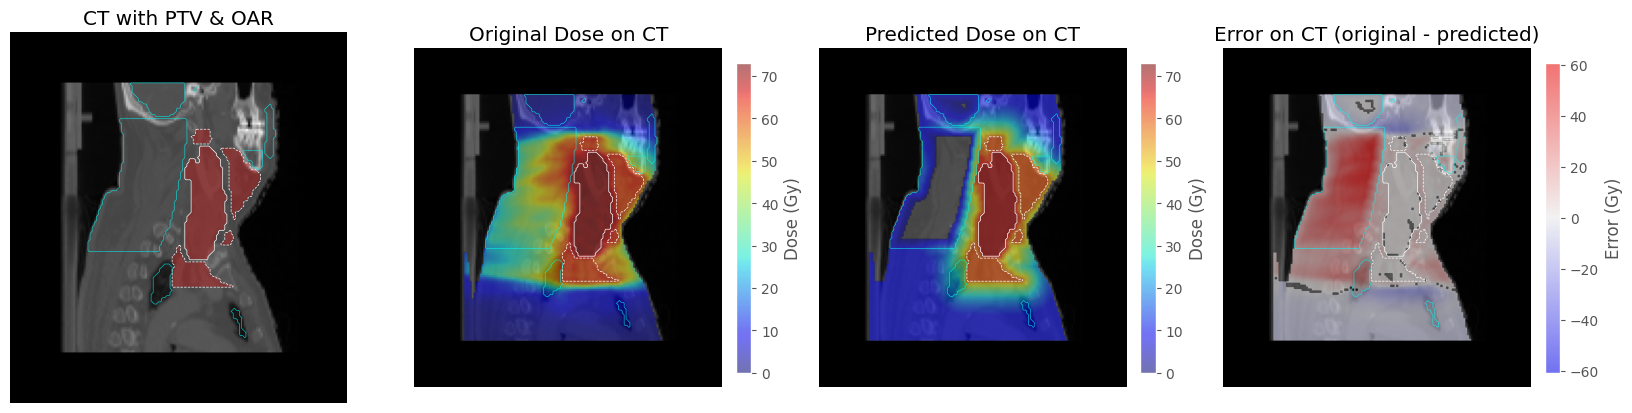

In [26]:
_ = analytical_dose.for_sample('HNC_044+A4Ac+MOS_5466').visualise_slice_with_ct(120)

## Analytical Dose with InDI

In [27]:
indi_ad_100 = ModelResults('144-indi-analytical-dose', 'indi-100', 199, 'test', dataset)
indi_ad_50 = ModelResults('144-indi-analytical-dose', 'indi-50', 199, 'test', dataset)
indi_ad_10 = ModelResults('144-indi-analytical-dose', 'indi-10', 199, 'test', dataset)
indi_ad_5 = ModelResults('144-indi-analytical-dose', 'indi-5', 199, 'test', dataset)
indi_ad_4 = ModelResults('144-indi-analytical-dose', 'indi-4', 199, 'test', dataset)
indi_ad_3 = ModelResults('144-indi-analytical-dose', 'indi-3', 199, 'test', dataset)
indi_ad_2 = ModelResults('144-indi-analytical-dose', 'indi-2', 199, 'test', dataset)
indi_ad_1 = ModelResults('144-indi-analytical-dose', 'indi-1', 199, 'test', dataset)

In [28]:
indi_ad_comparison = ModelComparison(
  [indi_ad_100, indi_ad_50, indi_ad_10, indi_ad_5, indi_ad_4, indi_ad_3, indi_ad_2, indi_ad_1],
  ['T=100', 'T=50', 'T=10', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1']
)

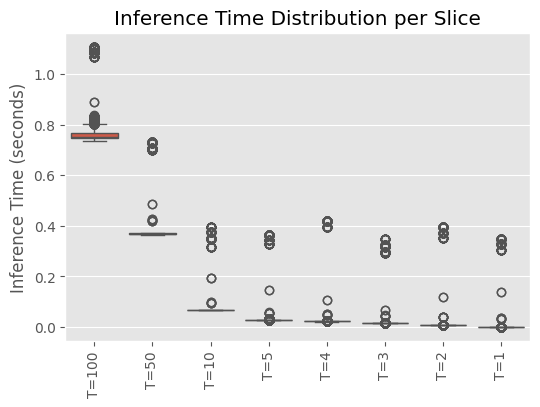

In [29]:
_ = indi_ad_comparison.plot_inference_times('slice', 'seconds')

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

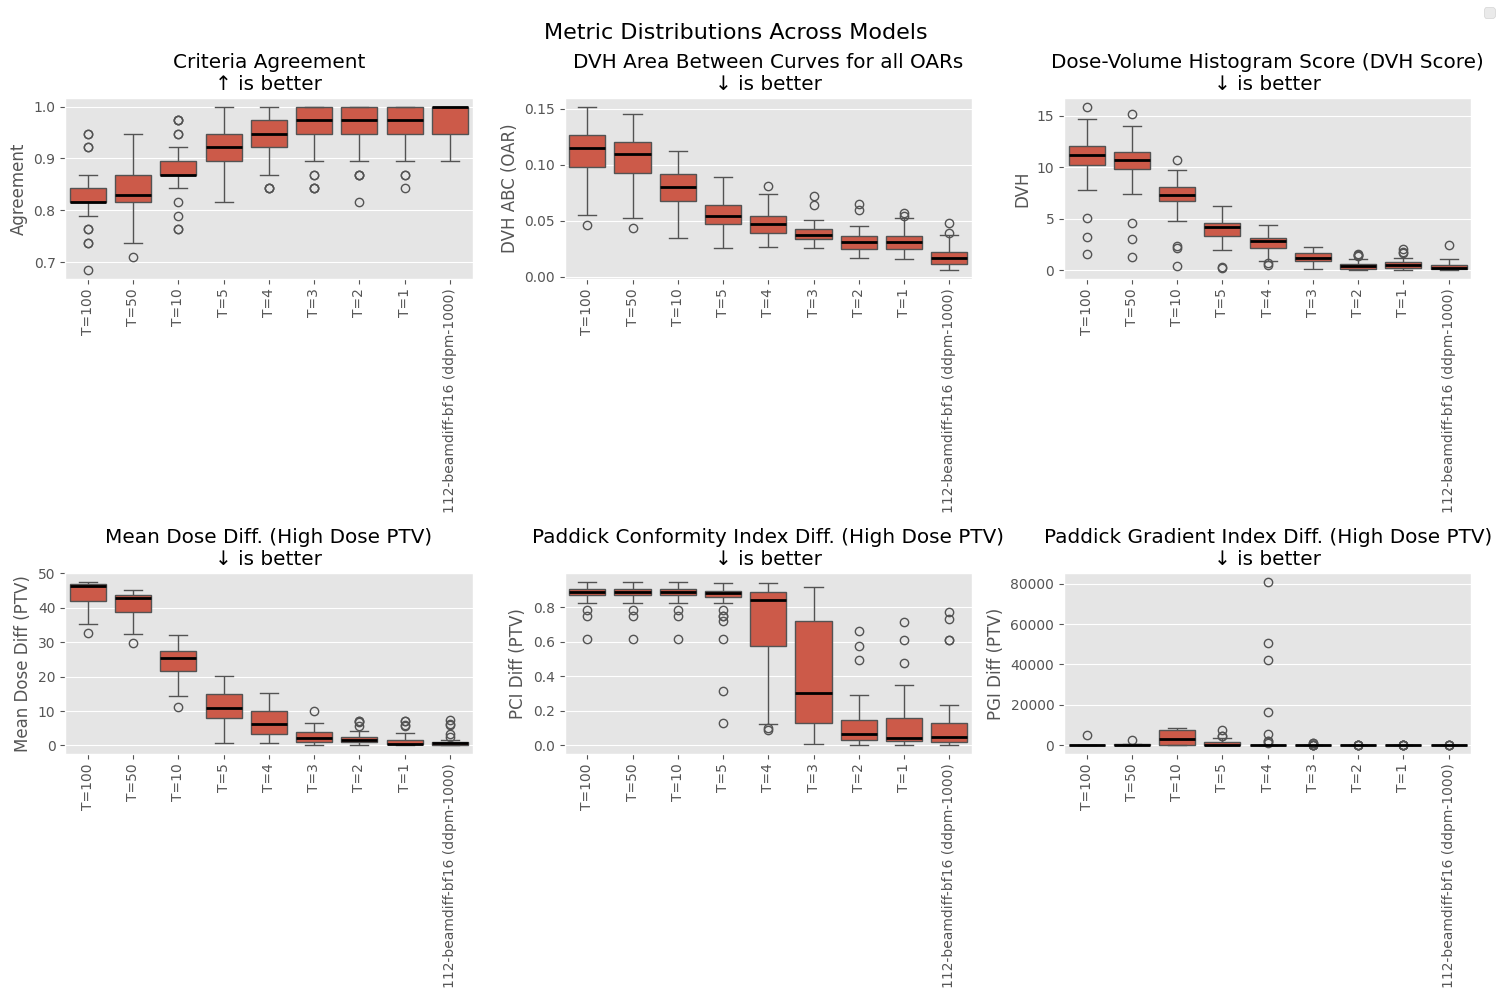

In [30]:
_ = (indi_ad_comparison + baseline).plot_metric_distributions(METRICS_PRED, outliers=True)